# Lab 8 – Responsible AI HS2026 (LIME and SHAP)
**Author:** Jann Erhardt (erharjan) · individual submission

In [12]:
# Packages: shap, lime, scikit-learn, pandas, matplotlib
# %pip install shap lime scikit-learn pandas matplotlib
# (if shap does not install on your Python version: the course kernel «xai» runs Python 3.11)

In [13]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42
TARGET = 'class'                 # quality score 3..8 in the raw data
CLASS_NAMES = ['Poor', 'Good']   # position = class label: 0 = poor, 1 = good

## Dataset and Machine Learning Task

The UCI Red Wine Quality dataset comprises 1,599 wine samples, each characterized by 11 physicochemical features. The original target variable, quality, is an integer score ranging from 3 to 8, indicating the perceived quality of the wine, with higher scores corresponding to better quality. For this assignment, convert the original target into a binary classification label: wines with a quality score of 6 or higher are assigned to class 1 (good), while wines with a quality score of 5 or lower are assigned to class 0 (poor). The tasks in this assignment focus on applying the post-hoc explainability methods LIME and SHAP to a machine learning model of your choice for this binary classification task.

Load the dataset:

In [14]:
data = fetch_openml('wine-quality-red', version=1, as_frame=True)
wine_df = data.frame

print(wine_df.shape)
wine_df.head()

(1599, 12)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,class
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### **TASKS** (5 Points):
1. Transform the target variable `class` in a binary target label (class 1 for scores 6 or above, class 0 for scores of 5 or below), split the data into a training and a test set (using an 80-20 split), train a model of your choice (e.g. gradient boosting, random forest, neural network) for the binary classification task and evaluate its performance. (0.5 point)
2. Create a LIME explainer for the trained model. Select four correctly classified test samples (two from each class). Generate and display the LIME explanation for each of the selected test instances, and discuss your findings. (1 point)
3. Apply the SHAP explainer on the trained model. Visualize the feature importances for the same four test samples chosen in Task 2 by generating both a force plot and a waterfall plot, and discuss your findings. (1 point)
4. Compare the SHAP local explanations to the LIME local explanations for one 'Good' and one 'Poor' sample. (1 point)
5. Plot the global SHAP importances of how each feature affects the model's prediction and discuss your finding.  (1 point)
6. Plot dependence plot for the features `alcohol` and `sulphates`. (0.5 point)

(The course notebook numbers the last task as a second «5.»; its solution cell is «Solution Task 6».)

## 1. Binary target, split, model, evaluation (0.5 pt)

In [15]:
def make_binary_target(quality, threshold=6):
    """Quality scores (Series) -> integer array/Series with 1 (good) if score >= threshold, else 0 (poor).
    Check wine_df[TARGET].dtype first: if OpenML delivers the score as a categorical column,
    a plain `>= 6` does not work on it."""
    if quality.dtype.name == 'category':
        quality = quality.astype(int)
    return (quality >= threshold).astype(int)


def split_data(X, y, test_size=0.2, random_state=RANDOM_STATE):
    """80/20 split -> X_train, X_test, y_train, y_test (DataFrames / Series, original index kept).
    Stratified, see the Task 1 discussion below."""
    return train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)


def train_model(X_train, y_train, random_state=RANDOM_STATE, hidden_layer_size=10):
    """Standardise features, then fit an MLP. The pipeline still offers predict()/predict_proba()
    on raw feature values, so LIME and SHAP explain the model in the original units."""
    mlp_model = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(hidden_layer_size,), max_iter=2000,
                      random_state=random_state),
    )
    mlp_model.fit(X_train, y_train)
    return mlp_model


def evaluate(model, X_test, y_test):
    """dict with the keys 'accuracy', 'precision', 'recall', 'f1', 'roc_auc' (positive class = good)
    and 'confusion_matrix' (2x2 array, rows = true class, columns = predicted class)."""
    y_pred = model.predict(X_test)
    return {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
        'confusion_matrix': confusion_matrix(y_test, y_pred)
    }

### Sanity checks (1)

In [16]:
assert list(make_binary_target(pd.Series(['3', '5', '6', '8'], dtype='category'))) == [0, 0, 1, 1]
assert list(make_binary_target(pd.Series([5, 6]))) == [0, 1]

X = wine_df.drop(columns=[TARGET])
y = pd.Series(np.asarray(make_binary_target(wine_df[TARGET])), index=wine_df.index, name='good')
assert X.shape == (1599, 11) and set(y.unique()) == {0, 1}

X_train, X_test, y_train, y_test = split_data(X, y)
assert (len(X_train), len(X_test)) == (1279, 320)                 # 80 / 20 of 1599
assert X_train.index.intersection(X_test.index).empty             # no sample in both sets
assert (X_test.index == y_test.index).all()

model = train_model(X_train, y_train)
assert model.predict_proba(X_test).shape == (320, 2)

metrics = evaluate(model, X_test, y_test)
assert np.asarray(metrics['confusion_matrix']).sum() == 320
assert metrics['accuracy'] > max(y_test.mean(), 1 - y_test.mean())  # beats «always predict the majority class»
print('ok')

ok


In [17]:
display(make_binary_target(wine_df[TARGET]).value_counts().rename({0: 'Poor', 1: 'Good'}))
X_train, X_test, y_train, y_test = split_data(X, y)
model = train_model(X_train, y_train, hidden_layer_size=40)
evaluate(model, X_test, y_test)

class
Good    855
Poor    744
Name: count, dtype: int64

{'accuracy': 0.778125,
 'precision': 0.8205128205128205,
 'recall': 0.7485380116959064,
 'f1': 0.7828746177370031,
 'roc_auc': 0.850896816986538,
 'confusion_matrix': array([[121,  28],
        [ 43, 128]])}

### Discussion (Task 1)

**Target and split.** Binarising `quality ≥ 6` gives 855 Good vs. 744 Poor wines (53.5 % / 46.5 %), so the classes are nearly balanced. I used a stratified 80/20 split (1,279 / 320 samples) so that both sets keep this ratio; with only 320 test samples, stratification prevents an accidental class shift from distorting the metrics.

**Model.** I chose a neural network on purpose: it is a black box, which is exactly the setting where post-hoc methods such as LIME and SHAP are needed. The model is an MLP with one hidden layer of 40 units (ReLU, Adam, max. 2,000 iterations) in a pipeline with a `StandardScaler`. The scaler is fitted on the training data only, and because it is part of the pipeline, LIME and SHAP work with the original feature units. Without scaling the MLP did not converge (accuracy 0.750, ROC-AUC 0.820). Early stopping ended training after 29 iterations and performed worse, and a 5-fold cross-validation on the training set over hidden size (10, 40) and L2 strength (10⁻⁴ to 1) changed the ROC-AUC by at most 0.01, so I kept the default regularisation.

**Performance.** On the test set the model reaches accuracy 0.778 (majority baseline: 0.534), precision 0.821, recall 0.749, F1 0.783 and ROC-AUC 0.851. It misclassifies 43 Good wines as Poor and 28 Poor wines as Good, so it is slightly conservative in calling a wine Good. The model is clearly better than chance but far from perfect; the explanations in the following tasks describe how this model decides, not the true determinants of wine quality.

## 2. LIME explanations for four test samples (1 pt)
Create a LIME explainer for the trained model. Select four correctly classified test samples (two from each class). Generate and display the LIME explanation for each of the selected test instances, and discuss your findings.

In [18]:
def pick_samples(model, X_test, y_test, n_per_class=2):
    """Positions (iloc, not index labels) of n_per_class correctly classified test samples per class:
    {1: [i, j], 0: [k, l]}  (1 = good, 0 = poor).
    Choice: the MOST CONFIDENT correct predictions per class (highest P(true class)). These are clear-cut
    cases, so the explanations show what the model relies on when it is sure, not borderline noise."""
    proba = model.predict_proba(X_test)
    y_true = np.asarray(y_test)
    y_pred = proba.argmax(axis=1)
    picked = {}
    for cls in [1, 0]:
        correct = np.where((y_true == cls) & (y_pred == cls))[0]
        most_confident = correct[np.argsort(-proba[correct, cls])]
        picked[cls] = [int(i) for i in most_confident[:n_per_class]]
    return picked


def make_lime_explainer(X_train, random_state=RANDOM_STATE):
    """LIME explainer for tabular data, built from the training data, with feature names and CLASS_NAMES.
    Must be reproducible: two explainers built with the same random_state give the same explanation."""
    return LimeTabularExplainer(
        X_train.values,
        feature_names=X_train.columns.tolist(),
        class_names=CLASS_NAMES,
        discretize_continuous=True,
        random_state=random_state
    )


def lime_explain(explainer, model, x, num_features=None):
    """LIME explanation object for ONE sample x (row of X_test as Series or 1D array), for class 1 (good).
    num_features=None -> use all features.
    LIME calls the prediction function with a plain numpy array of perturbed samples and expects
    class probabilities of shape (n, 2) back."""
    if isinstance(x, pd.Series):
        x = x.values
    predict_fn = lambda A: model.predict_proba(pd.DataFrame(A, columns=explainer.feature_names))
    return explainer.explain_instance(
        x,
        predict_fn,
        num_features=num_features or len(x),
        labels=[1]  # explain class 1 (good)
    )

### Sanity checks (2)

In [19]:
picked = pick_samples(model, X_test, y_test)
assert set(picked) == {0, 1} and all(len(v) == 2 for v in picked.values())
y_pred = np.asarray(model.predict(X_test))
for cls, positions in picked.items():
    for i in positions:
        assert y_test.iloc[i] == cls == y_pred[i], (cls, i)       # right class and correctly classified
assert len({i for v in picked.values() for i in v}) == 4          # four different samples

i0 = picked[1][0]
lime_explainer = make_lime_explainer(X_train)
exp = lime_explain(lime_explainer, model, X_test.iloc[i0])
weights = exp.as_list(label=1)                                    # [(condition, weight), ...] towards «good»
assert len(weights) == X_test.shape[1]                            # all 11 features
assert np.isclose(exp.predict_proba[1], model.predict_proba(X_test.iloc[[i0]])[0, 1])   # LIME explains the right row

exp_again = lime_explain(make_lime_explainer(X_train), model, X_test.iloc[i0])
assert exp_again.as_list(label=1) == weights, 'not reproducible – where does the randomness of LIME come from?'
print('ok')

ok


D:\Projects\zhaw-bachelor\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
D:\Projects\zhaw-bachelor\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


D:\Projects\zhaw-bachelor\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
D:\Projects\zhaw-bachelor\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
D:\Projects\zhaw-bachelor\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
D:\Projects\zhaw-bachelor\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


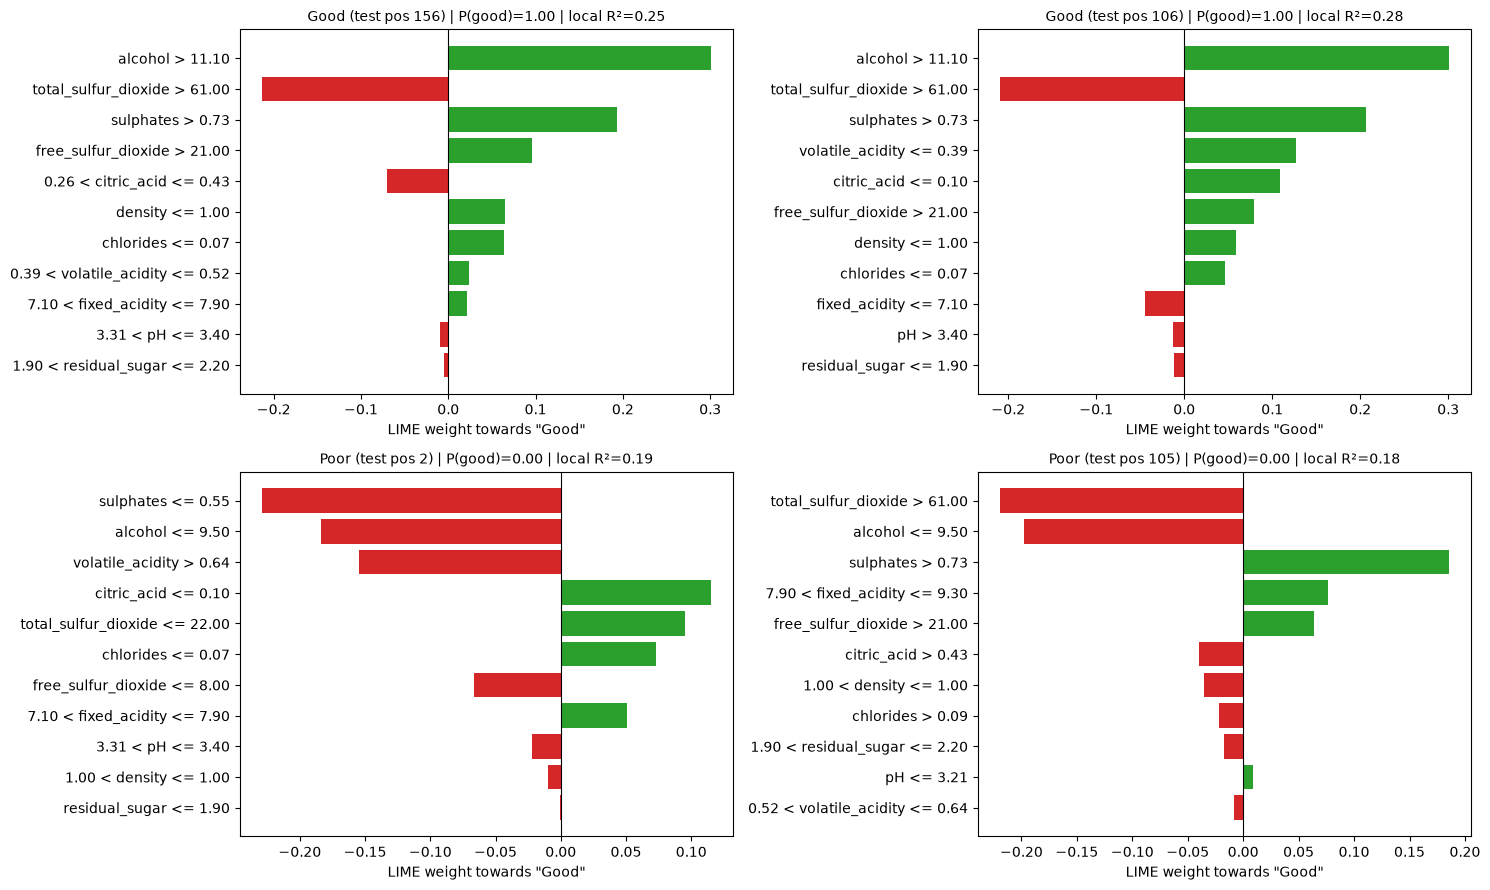

,true class,model P(good),surrogate P(good),intercept,local R²
156,Good,1.000,0.881,0.418,0.246
106,Good,1.000,1.018,0.368,0.283
2,Poor,0.000,0.278,0.611,0.187
105,Poor,0.004,0.370,0.576,0.179


In [20]:
# LIME explanation for the four samples in `picked`, plus the quality of each local fit
lime_explainer = make_lime_explainer(X_train)
order = [(1, i) for i in picked[1]] + [(0, i) for i in picked[0]]   # Good, Good, Poor, Poor
lime_exps = {}                                                        # reused in Task 4

fig, axs = plt.subplots(2, 2, figsize=(15, 9))
for ax, (cls, i) in zip(axs.flat, order):
    exp_i = lime_explain(lime_explainer, model, X_test.iloc[i])
    lime_exps[i] = exp_i
    conds, w = zip(*exp_i.as_list(label=1)[::-1])                     # largest |weight| ends up on top
    ax.barh(conds, w, color=['tab:green' if v > 0 else 'tab:red' for v in w])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{CLASS_NAMES[cls]} (test pos {i}) | P(good)={exp_i.predict_proba[1]:.2f} '
                 f'| local R²={exp_i.score:.2f}', fontsize=10)
    ax.set_xlabel('LIME weight towards "Good"')
fig.tight_layout()
plt.show()

pd.DataFrame({
    'true class':        [CLASS_NAMES[c] for c, _ in order],
    'model P(good)':     [lime_exps[i].predict_proba[1] for _, i in order],
    'surrogate P(good)': [lime_exps[i].local_pred[0] for _, i in order],
    'intercept':         [lime_exps[i].intercept[1] for _, i in order],
    'local R²':          [lime_exps[i].score for _, i in order],
}, index=[i for _, i in order]).round(3)

### Discussion (Task 2)

**Sample choice.** For each class I took the two correctly classified test samples with the highest predicted probability for their true class (positions 156, 106 = Good; 2, 105 = Poor). These clear-cut cases show what the model relies on when it is confident.

**Findings.** Across all four samples the same features dominate: `alcohol` is the strongest driver (`alcohol > 11.1` → Good, `alcohol ≤ 9.5` → Poor), followed by `sulphates` (high → Good, low → Poor), `total_sulfur_dioxide > 61` (→ Poor) and `volatile_acidity > 0.64` (→ Poor). This is consistent with oenology: higher alcohol and sulphates are associated with better-rated wines, while high volatile acidity (vinegar taste) and high SO₂ are faults. The explanations are not one-sided: Good sample 156 has a strong negative contribution from its high SO₂ and Poor sample 105 a positive one from its high sulphates. The prediction is the net result of competing evidence.

**Reliability.** The local surrogate fits only moderately (R² = 0.18–0.28), and its prediction deviates from the model's (e.g. 0.28 vs. 0.00 for sample 2). Because the selected samples are very confident, the MLP output is saturated in their neighbourhood, and LIME's perturbations, sampled from the training distribution, cover regions where the model behaves non-linearly. The ranking and sign of the top features are therefore more trustworthy than the exact weights. LIME also explains with discretised conditions (quartile bins), so it states e.g. that "alcohol is in the top quartile" and not how much each additional % of alcohol matters.

## 3. SHAP explanations for the same four samples (1 pt)
Apply the SHAP explainer on the trained model. Visualize the feature importances for the same four test samples chosen in Task 2 by generating both a force plot and a waterfall plot, and discuss your findings.

In [21]:
SHAP_BACKGROUND_SIZE = 100


def _p_good(model, feature_names):
    """Wrap the model so SHAP sees a function: raw feature matrix -> P(good).
    SHAP passes plain numpy arrays; the wrapper restores the column names for the sklearn pipeline."""
    def f(A):
        return model.predict_proba(pd.DataFrame(np.asarray(A), columns=feature_names))[:, 1]
    return f


def make_shap_explanation(model, X_background, X_explain, explainer='permutation'):
    """shap.Explanation for the rows of X_explain, for P(good) (a probability, NOT log-odds).
    Model-agnostic explainers, because an MLP has no exact fast explainer like TreeExplainer.
    'Missing' features are filled in from a background sample of 100 training rows,
    so the base value = mean P(good) over that background.
      explainer='permutation': PermutationExplainer (antithetic permutations, exactly additive)
      explainer='kernel':      KernelExplainer (Shapley-weighted linear regression over coalitions)"""
    feature_names = list(X_background.columns)
    background = shap.sample(X_background, SHAP_BACKGROUND_SIZE, random_state=RANDOM_STATE)
    f = _p_good(model, feature_names)

    if explainer == 'permutation':
        exp = shap.PermutationExplainer(f, shap.maskers.Independent(background), seed=RANDOM_STATE)
        return exp(X_explain, silent=True)

    if explainer == 'kernel':
        np.random.seed(RANDOM_STATE)  # KernelExplainer samples coalitions with np.random
        exp = shap.KernelExplainer(f, background)
        values = exp.shap_values(X_explain, silent=True)
        return shap.Explanation(values=np.asarray(values),
                                base_values=np.full(len(X_explain), exp.expected_value),
                                data=np.asarray(X_explain), feature_names=feature_names)

    raise ValueError(f"unknown explainer: {explainer!r}")


def model_output(model, X):
    """P(good) for the rows of X, the output that make_shap_explanation() explains."""
    return model.predict_proba(X)[:, 1]

### Sanity checks (3)

In [22]:
sv = make_shap_explanation(model, X_train, X_test)
assert sv.values.shape == X_test.shape, sv.values.shape           # one output only: class «good»
assert np.shape(sv.base_values) == (len(X_test),)

# the property that makes SHAP «fair»: base value + sum of the contributions = explained model output
reconstructed = sv.base_values + sv.values.sum(axis=1)
gap = np.abs(reconstructed - model_output(model, X_test)).max()
assert gap < 1e-2, gap
print('ok – base value:', float(np.mean(sv.base_values)))

ok – base value: 0.5211180984796504


### Permutation vs. Kernel SHAP
Same model, same 100 background rows, same 320 test rows: only the estimation method differs.

In [23]:
runs = {}
for name in ['permutation', 'kernel']:
    t0 = time.perf_counter()
    e = make_shap_explanation(model, X_train, X_test, explainer=name)
    runs[name] = (e, time.perf_counter() - t0)

p_out = model_output(model, X_test)
display(pd.DataFrame({name: {
    'runtime [s]':        t,
    'base value':         float(np.mean(e.base_values)),
    'max additivity gap': float(np.abs(e.base_values + e.values.sum(axis=1) - p_out).max()),
} for name, (e, t) in runs.items()}).T)

perm, kern = runs['permutation'][0].values, runs['kernel'][0].values
print(f'Pearson r over all {perm.size} SHAP values: {np.corrcoef(perm.ravel(), kern.ravel())[0, 1]:.4f}')
print(f'mean |difference|: {np.abs(perm - kern).mean():.4f}   max |difference|: {np.abs(perm - kern).max():.4f}')

# global view: mean |SHAP| per feature and per-feature agreement
display(pd.DataFrame({
    'perm mean|SHAP|':   np.abs(perm).mean(axis=0),
    'kernel mean|SHAP|': np.abs(kern).mean(axis=0),
    'per-feature r':     [np.corrcoef(perm[:, j], kern[:, j])[0, 1] for j in range(perm.shape[1])],
}, index=X_test.columns).sort_values('perm mean|SHAP|', ascending=False).round(4))

# local view: top-3 features for the four samples picked in Task 2
cols = np.array(X_test.columns)
display(pd.DataFrame({
    f'{CLASS_NAMES[cls]} (pos {i})': {
        'permutation top-3': ', '.join(cols[np.argsort(-np.abs(perm[i]))[:3]]),
        'kernel top-3':      ', '.join(cols[np.argsort(-np.abs(kern[i]))[:3]]),
    } for cls in [1, 0] for i in picked[cls]
}).T)

,runtime [s],base value,max additivity gap
permutation,7.838327,0.521118,2.331468e-15
kernel,17.839269,0.521118,2.442491e-15


Pearson r over all 3520 SHAP values: 0.9961
mean |difference|: 0.0056   max |difference|: 0.0686


,perm mean|SHAP|,kernel mean|SHAP|,per-feature r
alcohol,0.1497,0.1485,0.9986
sulphates,0.0989,0.0985,0.9979
volatile_acidity,0.0881,0.0874,0.9972
total_sulfur_dioxide,0.0688,0.0685,0.9970
citric_acid,0.0676,0.0667,0.9928
fixed_acidity,0.0581,0.0572,0.9934
free_sulfur_dioxide,0.0478,0.0471,0.9920
density,0.0400,0.0397,0.9926
pH,0.0376,0.0360,0.9883
chlorides,0.0271,0.0257,0.9896


,permutation top-3,kernel top-3
Good (pos 156),"alcohol, sulphates, free_sulfur_dioxide","alcohol, sulphates, free_sulfur_dioxide"
Good (pos 106),"alcohol, sulphates, fixed_acidity","alcohol, density, sulphates"
Poor (pos 2),"sulphates, volatile_acidity, alcohol","sulphates, volatile_acidity, alcohol"
Poor (pos 105),"total_sulfur_dioxide, alcohol, chlorides","total_sulfur_dioxide, alcohol, sulphates"


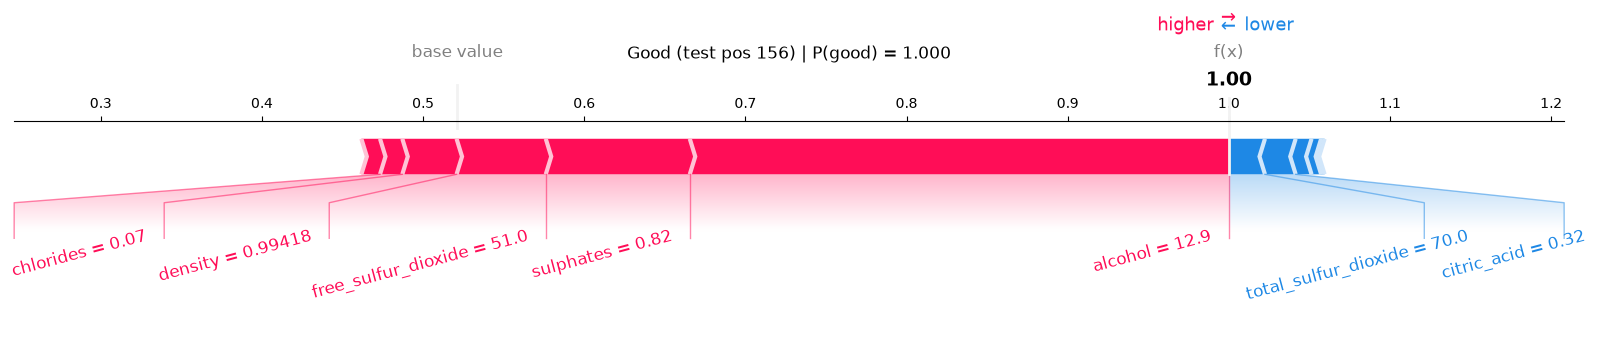

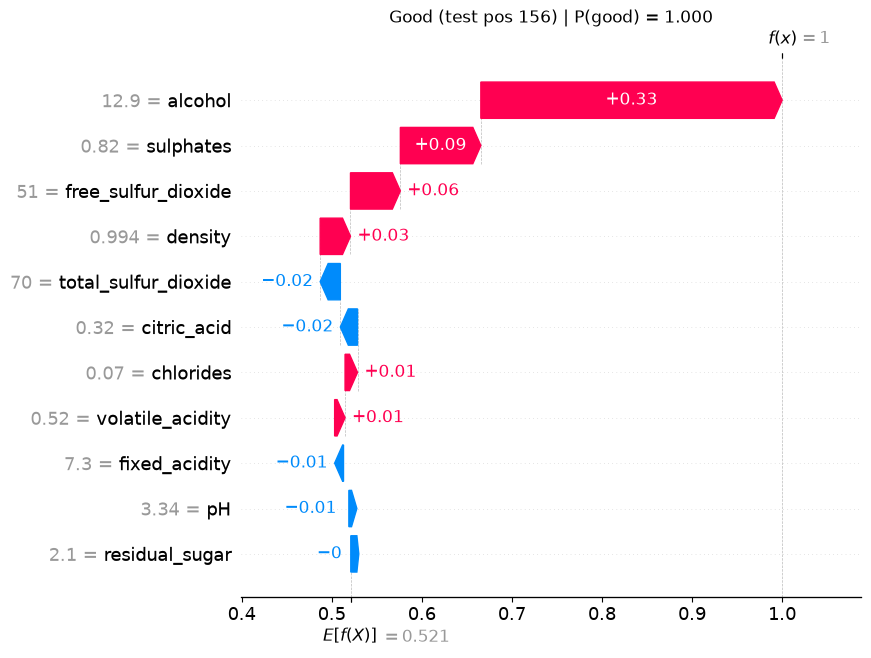

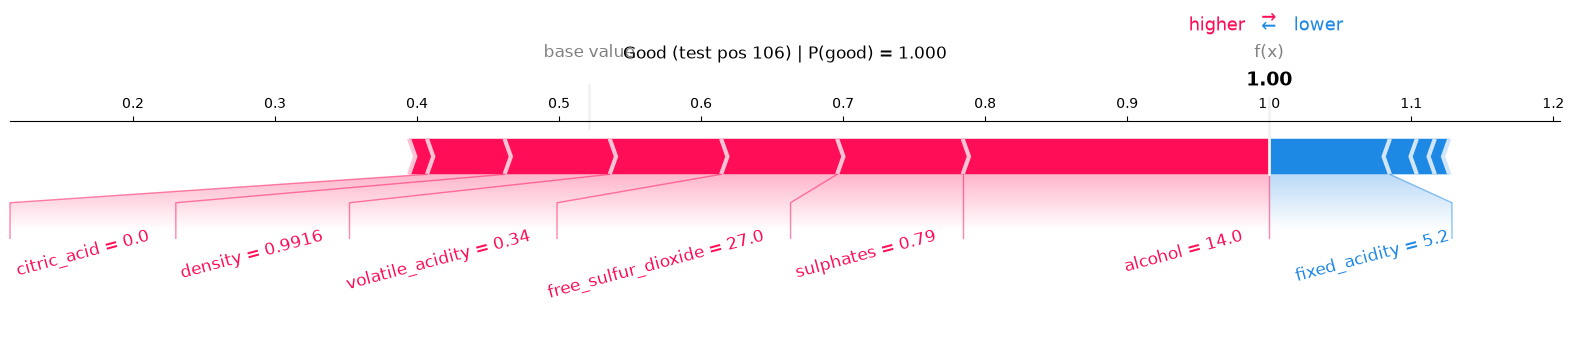

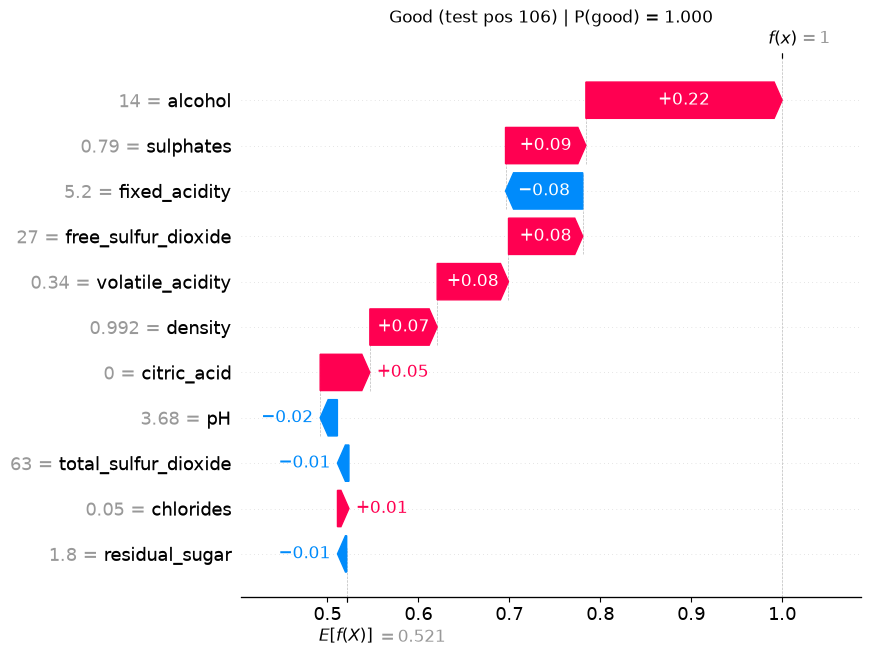

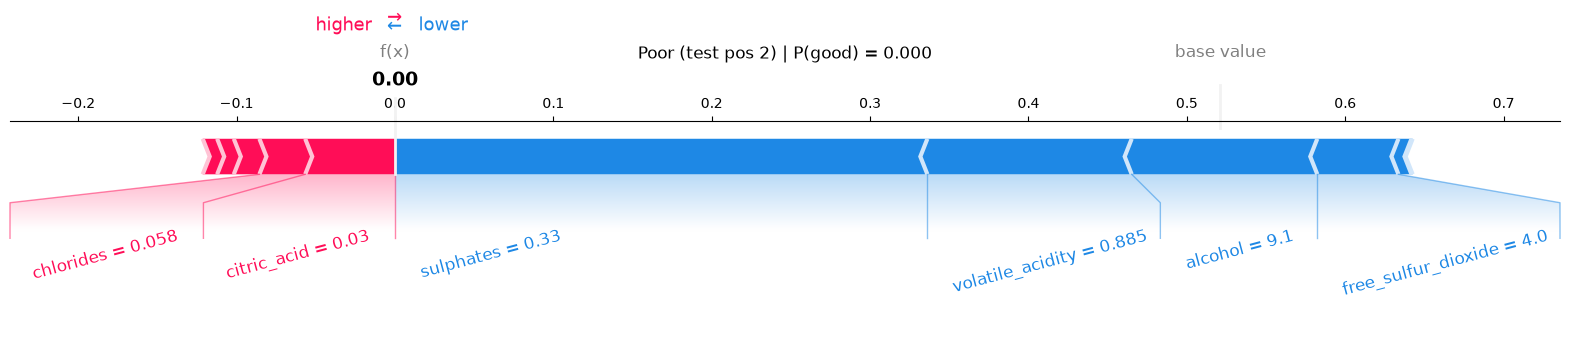

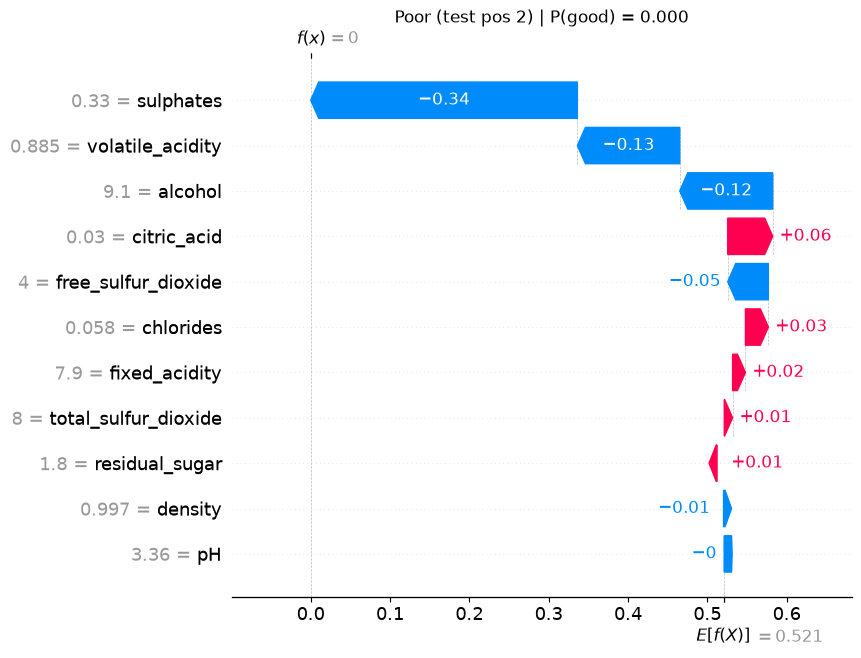

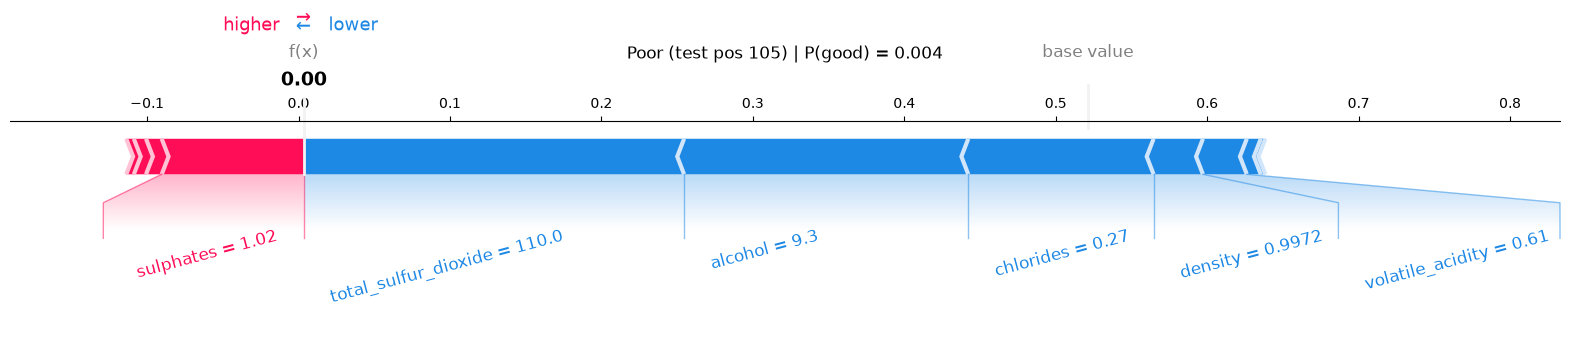

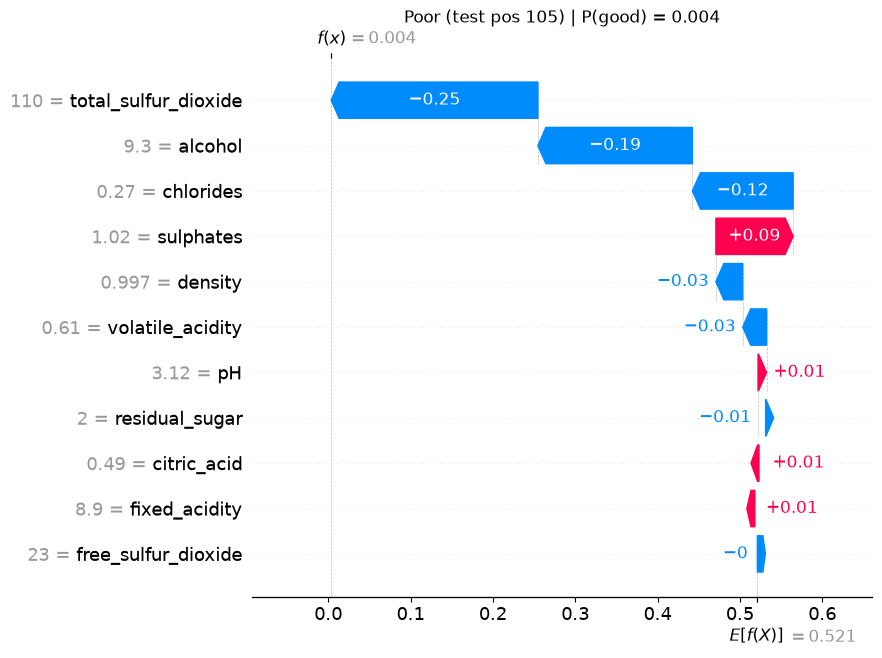

In [27]:
# Force plot + waterfall plot for the four samples in `picked` (Permutation SHAP, output = P(good))
for cls, i in order:
    title = f'{CLASS_NAMES[cls]} (test pos {i}) | P(good) = {model_output(model, X_test.iloc[[i]])[0]:.3f}'

    shap.plots.force(sv[i], matplotlib=True, show=False, figsize=(20, 3), text_rotation=15)
    plt.title(title, pad=45)
    plt.show()

    shap.plots.waterfall(sv[i], max_display=12, show=False)
    plt.title(title)
    plt.show()

### Discussion (Task 3)

**Setup.** SHAP explains P(good) of the MLP (probability, not log-odds) with a model-agnostic PermutationExplainer; absent features are filled in from 100 random training rows. The base value E[f(X)] = 0.521 is the mean prediction over that background, and for every sample base value + Σ SHAP values reproduces the model output exactly (additivity gap ≈ 10⁻¹⁵).

**Permutation vs. Kernel SHAP.** Both explainers estimate the same Shapley values with different sampling strategies. On all 320 test rows they agree almost perfectly (Pearson r = 0.996, mean |Δ| = 0.006, identical global feature ranking), and their top-3 features differ only for samples 106 and 105, in third place, where several features have similarly small contributions. Permutation was ~2× faster (7.8 s vs. 17.6 s), so I use it for the rest of the lab.

**Findings.** The plots confirm the drivers found with LIME: high `alcohol` (+0.33 for sample 156, +0.22 for 106) and `sulphates` push towards Good; very low `sulphates` (−0.34 for sample 2), high `volatile_acidity`, low `alcohol` and high `total_sulfur_dioxide` (−0.25 for sample 105) push towards Poor. The two Good samples reach P ≈ 1 differently: sample 156 is dominated by alcohol alone, while 106 accumulates many medium contributions, which the force plot makes visible at a glance and the waterfall plot quantifies. Because SHAP works with actual feature values instead of bins, extreme values are weighted accordingly: `chlorides = 0.27` (≈3× the typical value) costs sample 105 −0.12, while LIME's condition `chlorides > 0.09` gave only −0.02. Conversely, `total_sulfur_dioxide = 70` gets only −0.02 for sample 156 in SHAP versus −0.21 in LIME: once the other features have pushed the output into saturation, SO₂ barely changes it, an interaction effect that SHAP's averaging over feature orderings captures and LIME's global linear surrogate does not.

**Limitation.** The Independent masker treats features as independent and therefore also evaluates unrealistic wines (e.g. high alcohol combined with high density, although the two are strongly negatively correlated), which can distort the attributions of correlated features.

## 4. SHAP vs. LIME for one good and one poor sample (1 pt)
Compare the SHAP local explanations to the LIME local explanations for one 'Good' and one 'Poor' sample.

In [28]:
def lime_vs_shap_table(lime_exp, shap_row, feature_names):
    """DataFrame for ONE sample, index = feature name, columns:
    lime_weight, shap_value, lime_rank, shap_rank   (rank 1 = largest absolute value, ranks 1..n without ties).
    LIME's as_list() gives conditions ('alcohol > 11.10'); as_map() gives the same weights keyed by
    feature position, which lines them up with the SHAP values."""
    lime_w = dict(lime_exp.as_map()[1])                    # {feature position: weight} for class 1 (good)
    table = pd.DataFrame({
        'lime_weight': [lime_w[j] for j in range(len(feature_names))],
        'shap_value':  np.asarray(shap_row.values),
    }, index=feature_names)
    for col, rank_col in [('lime_weight', 'lime_rank'), ('shap_value', 'shap_rank')]:
        table[rank_col] = table[col].abs().rank(ascending=False, method='first').astype(int)
    return table.sort_values('shap_rank')


def topk_agreement(table, k=5):
    """dict with
    'feature_agreement': share of the top-k features (by rank) that LIME and SHAP have in common,
    'sign_agreement':    share of the top-k features that are common AND have the same sign.
    Both are divided by k, so sign_agreement <= feature_agreement."""
    lime_top = set(table.index[table['lime_rank'] <= k])
    shap_top = set(table.index[table['shap_rank'] <= k])
    common = lime_top & shap_top
    same_sign = [f for f in common
                 if np.sign(table.at[f, 'lime_weight']) == np.sign(table.at[f, 'shap_value'])]
    return {'feature_agreement': len(common) / k, 'sign_agreement': len(same_sign) / k}

### Sanity checks (4)

In [29]:
toy = pd.DataFrame({'lime_weight': [0.30, -0.20, 0.10, 0.01], 'shap_value': [0.25, -0.05, -0.15, -0.02]},
                   index=['a', 'b', 'c', 'd'])
toy['lime_rank'] = [1, 2, 3, 4]
toy['shap_rank'] = [1, 3, 2, 4]
r = topk_agreement(toy, k=2)       # LIME top-2 = {a, b}, SHAP top-2 = {a, c} -> only a is common
assert np.isclose(r['feature_agreement'], 1 / 2) and np.isclose(r['sign_agreement'], 1 / 2)
r = topk_agreement(toy, k=3)       # both top-3 = {a, b, c}; c has opposite signs
assert np.isclose(r['feature_agreement'], 1.0) and np.isclose(r['sign_agreement'], 2 / 3)

tab = lime_vs_shap_table(exp, sv[i0], list(X_test.columns))
assert set(tab.index) == set(X_test.columns)
n = X_test.shape[1]
assert sorted(tab['lime_rank']) == list(range(1, n + 1)) and sorted(tab['shap_rank']) == list(range(1, n + 1))
assert np.allclose(tab['shap_value'].reindex(X_test.columns), sv[i0].values)
assert np.isclose(tab['lime_weight'].abs().max(), max(abs(w) for _, w in weights))
print('ok')

ok


,feature_agreement @5,sign_agreement @5,feature_agreement @3,sign_agreement @3
Good (pos 156),0.8,0.8,0.67,0.67
Good (pos 106),0.6,0.6,0.67,0.67
Poor (pos 2),0.8,0.8,1.00,1.00
Poor (pos 105),0.6,0.6,0.67,0.67


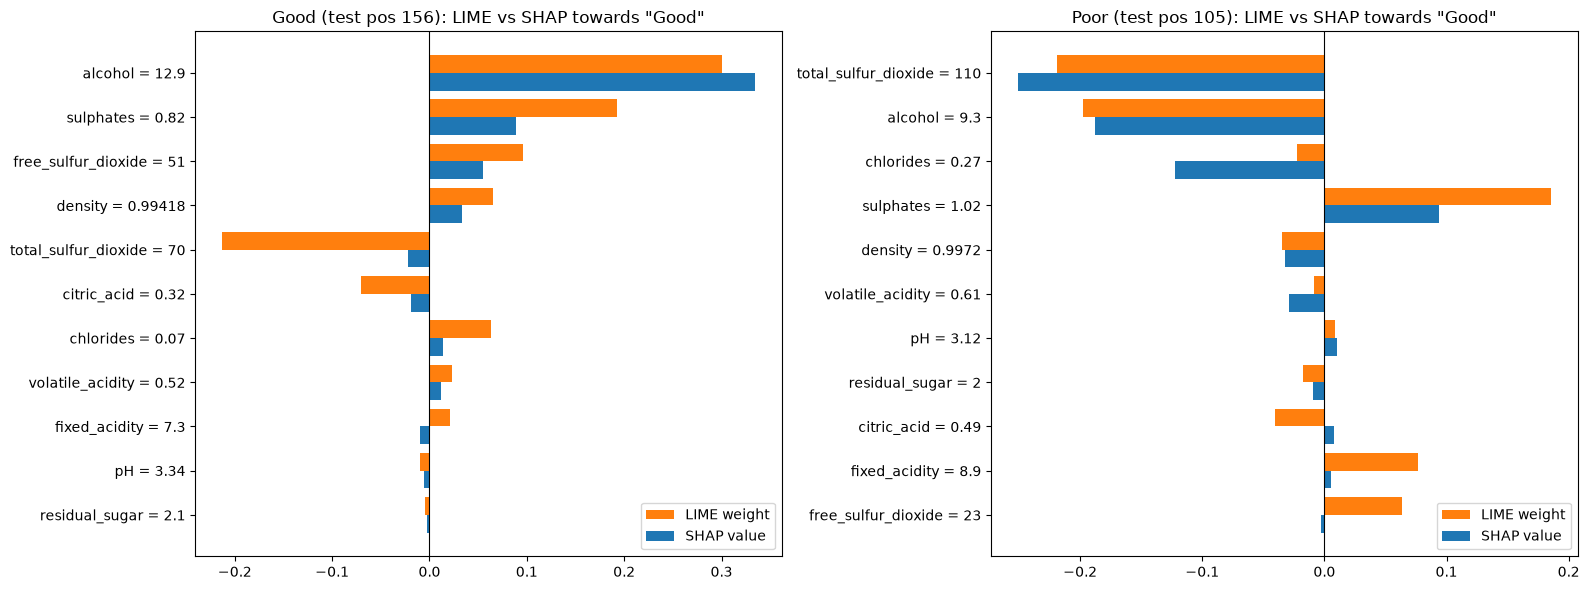

Good (pos 156)


,lime_weight,shap_value,lime_rank,shap_rank
alcohol,0.301,0.335,1,1
sulphates,0.193,0.089,3,2
free_sulfur_dioxide,0.096,0.055,4,3
density,0.065,0.034,6,4
total_sulfur_dioxide,-0.213,-0.022,2,5
citric_acid,-0.071,-0.019,5,6
chlorides,0.063,0.014,7,7
volatile_acidity,0.023,0.012,8,8
fixed_acidity,0.021,-0.010,9,9
pH,-0.010,-0.006,10,10


Poor (pos 105)


,lime_weight,shap_value,lime_rank,shap_rank
total_sulfur_dioxide,-0.219,-0.251,1,1
alcohol,-0.198,-0.188,2,2
chlorides,-0.022,-0.122,8,3
sulphates,0.185,0.094,3,4
density,-0.035,-0.033,7,5
volatile_acidity,-0.008,-0.029,11,6
pH,0.008,0.010,10,7
residual_sugar,-0.017,-0.009,9,8
citric_acid,-0.040,0.008,6,9
fixed_acidity,0.076,0.005,4,10


In [30]:
# LIME vs SHAP: top-k agreement for all four samples, detailed side-by-side for one Good and one Poor
feature_names = list(X_test.columns)
tables = {i: lime_vs_shap_table(lime_exps[i], sv[i], feature_names) for _, i in order}

display(pd.DataFrame({
    f'{CLASS_NAMES[cls]} (pos {i})': {
        **{f'{m} @5': v for m, v in topk_agreement(tables[i], k=5).items()},
        **{f'{m} @3': v for m, v in topk_agreement(tables[i], k=3).items()},
    } for cls, i in order
}).T.round(2))

compare = [(1, picked[1][0]), (0, picked[0][1])]          # Good pos 156, Poor pos 105
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for ax, (cls, i) in zip(axs, compare):
    tab = tables[i].iloc[::-1]                             # largest |SHAP| on top
    y_pos = np.arange(len(tab))
    ax.barh(y_pos + 0.2, tab['lime_weight'], height=0.4, color='tab:orange', label='LIME weight')
    ax.barh(y_pos - 0.2, tab['shap_value'],  height=0.4, color='tab:blue',   label='SHAP value')
    ax.set_yticks(y_pos, [f'{f} = {X_test.iloc[i][f]:g}' for f in tab.index])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{CLASS_NAMES[cls]} (test pos {i}): LIME vs SHAP towards "Good"')
    ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

for cls, i in compare:
    print(f'{CLASS_NAMES[cls]} (pos {i})')
    display(tables[i].round(3))

### Discussion (Task 4)

**Comparison set-up.** For each of the four samples I computed the top-k agreement between LIME and SHAP (k = 3 and 5) and compared one Good (pos 156) and one Poor (pos 105) sample in detail. LIME weights and SHAP values are both in units of P(good) but are not strictly comparable: a LIME weight is the coefficient of a 0/1 bin indicator in a poorly fitting surrogate (R² ≈ 0.2), whereas a SHAP value is the exact contribution of the feature value relative to the background mean. I therefore compare mainly rankings and signs.

**Agreement.** Both methods always agree on the most important feature (`alcohol` for 156, `total_sulfur_dioxide` for 105) and on the direction of all features that appear in both top-5 lists (sign agreement = feature agreement for all four samples). Top-5 feature agreement is 0.6–0.8, top-3 agreement 0.67–1.0. Sign disagreements only occur among the lowest-ranked features with negligible SHAP values (e.g. `free_sulfur_dioxide` in sample 105: LIME +0.064, SHAP −0.003).

**Disagreement and its cause.** The LIME weight of a condition is almost identical across samples: `alcohol > 11.10` gets 0.301 in both Good samples, `total_sulfur_dioxide > 61` gets −0.21 in all three samples where it applies. With `discretize_continuous=True`, LIME draws its perturbations from the training distribution of each bin rather than from the neighbourhood of the instance, so the instance only decides which bin indicators are active. In this setting LIME effectively reports an average effect per bin, while SHAP is genuinely instance-specific. This explains the two largest disagreements:
- *Sample 156, `total_sulfur_dioxide = 70`:* LIME −0.21 (rank 2) vs. SHAP −0.02 (rank 5). On average, high SO₂ hurts, but for this wine the other features have already pushed P(good) into saturation, so SO₂ barely changes the output.
- *Sample 105, `chlorides = 0.27`:* LIME −0.02 (rank 8) vs. SHAP −0.12 (rank 3). The value is about three times the typical chloride level, but LIME's bin `chlorides > 0.09` cannot distinguish it from 0.10.

**Conclusion.** For "which features matter and in which direction" both methods tell the same story, which increases trust in it. For "how much does this feature matter for *this* wine", SHAP is more reliable here: it uses the actual feature values, is exactly additive, and is stable (two SHAP estimators agreed with r = 0.996), whereas LIME's answer depends on the discretisation and its surrogate fits poorly at saturated predictions.

## 5. Global SHAP importances (1 pt)
Plot the global SHAP importances of how each feature affects the model's prediction and discuss your finding.

In [31]:
def global_importance(sv):
    """Series: mean absolute SHAP value per feature over all explained samples,
    index = feature names, sorted from most to least important."""
    return (pd.Series(np.abs(sv.values).mean(axis=0), index=sv.feature_names, name='mean |SHAP|')
              .sort_values(ascending=False))

### Sanity checks (5)

In [32]:
gi = global_importance(sv)
assert set(gi.index) == set(X_test.columns)
assert gi.is_monotonic_decreasing and (gi >= 0).all()
assert np.isclose(gi.sum(), np.abs(sv.values).mean(axis=0).sum())
print(gi)

alcohol                 0.149699
sulphates               0.098882
volatile_acidity        0.088144
total_sulfur_dioxide    0.068848
citric_acid             0.067613
fixed_acidity           0.058095
free_sulfur_dioxide     0.047755
density                 0.039970
pH                      0.037593
chlorides               0.027089
residual_sugar          0.024828
Name: mean |SHAP|, dtype: float64


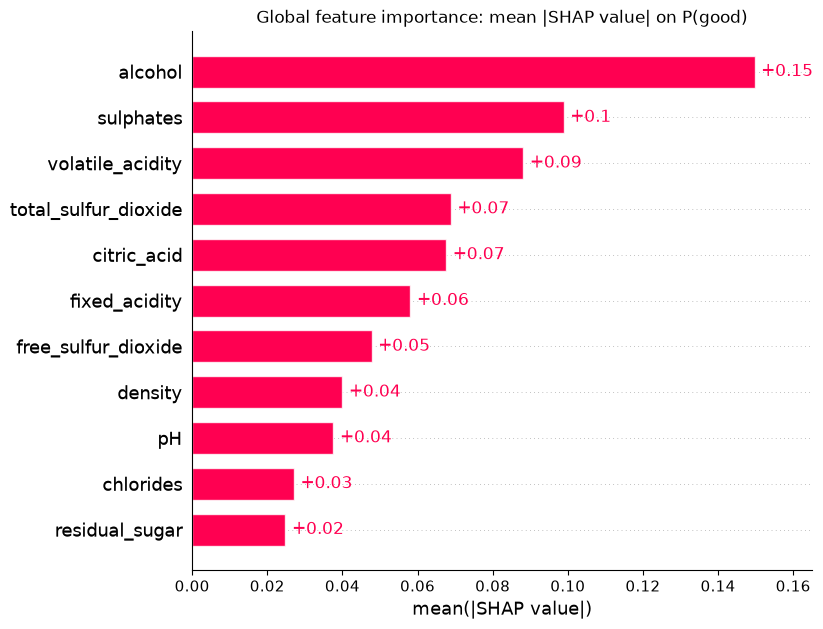

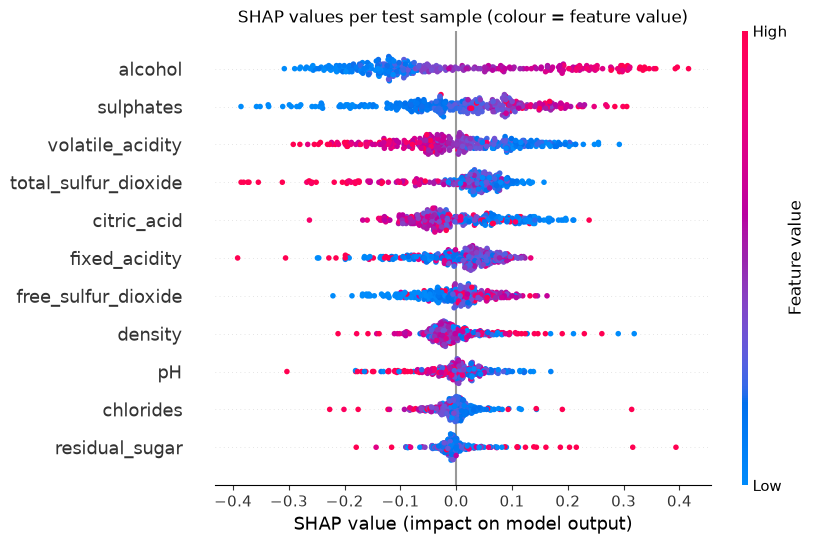

In [33]:
# Global SHAP plots over all 320 test samples (Permutation SHAP, output = P(good))
shap.plots.bar(sv, max_display=X_test.shape[1], show=False)
plt.title('Global feature importance: mean |SHAP value| on P(good)')
plt.show()

shap.plots.beeswarm(sv, max_display=X_test.shape[1], show=False)
plt.title('SHAP values per test sample (colour = feature value)')
plt.show()

### Discussion (Task 5)

**Ranking.** Averaged over the 320 test samples, `alcohol` is by far the most important feature (mean |SHAP| = 0.150 in P(good)), followed by `sulphates` (0.099) and `volatile_acidity` (0.088). `total_sulfur_dioxide` and `citric_acid` (≈0.07) form a middle group; `chlorides` and `residual_sugar` matter least (≈0.025). The ranking is identical for the Kernel explainer (Task 3) and matches the features that dominated the local LIME and SHAP explanations.

**Direction.** The beeswarm plot shows clean monotonic effects for the top three features (Spearman correlation between feature value and SHAP value: `alcohol` +0.91, `sulphates` +0.92, `volatile_acidity` −0.92), consistent with the strongest raw correlations with the label in the training data. Several effects are asymmetric: very high `total_sulfur_dioxide` or very low `sulphates` cost up to −0.4, while favourable values add only little. For `citric_acid` (model: −0.63, raw data: +0.15) and `free_sulfur_dioxide` (model: +0.70, raw data: −0.06) the model's direction is opposite to the marginal correlation. Citric acid is strongly correlated with low volatile acidity (ρ = −0.61), so its positive raw correlation is likely explained by volatile acidity, which the model uses directly. Free SO₂ is part of total SO₂, so for a given total, a higher free share is favourable. SHAP thus describes how the model uses a feature *given the others*, not the marginal or causal effect. Because the Independent masker ignores the strong correlations among the acidity-related features (|ρ| = 0.5–0.7), the attributions of these features should be interpreted with caution.

**Global vs. local.** Mean |SHAP| hides rare but strong effects: `chlorides` ranks 10th globally, yet it was the third most important feature for sample 105 (−0.12), visible in the beeswarm as isolated outliers. Global importance answers "what does the model rely on in general", not "what drove this particular prediction".

## 6. Dependence plots for `alcohol` and `sulphates` (0.5 pt)
Plot dependence plot for the features `alcohol` and `sulphates`.

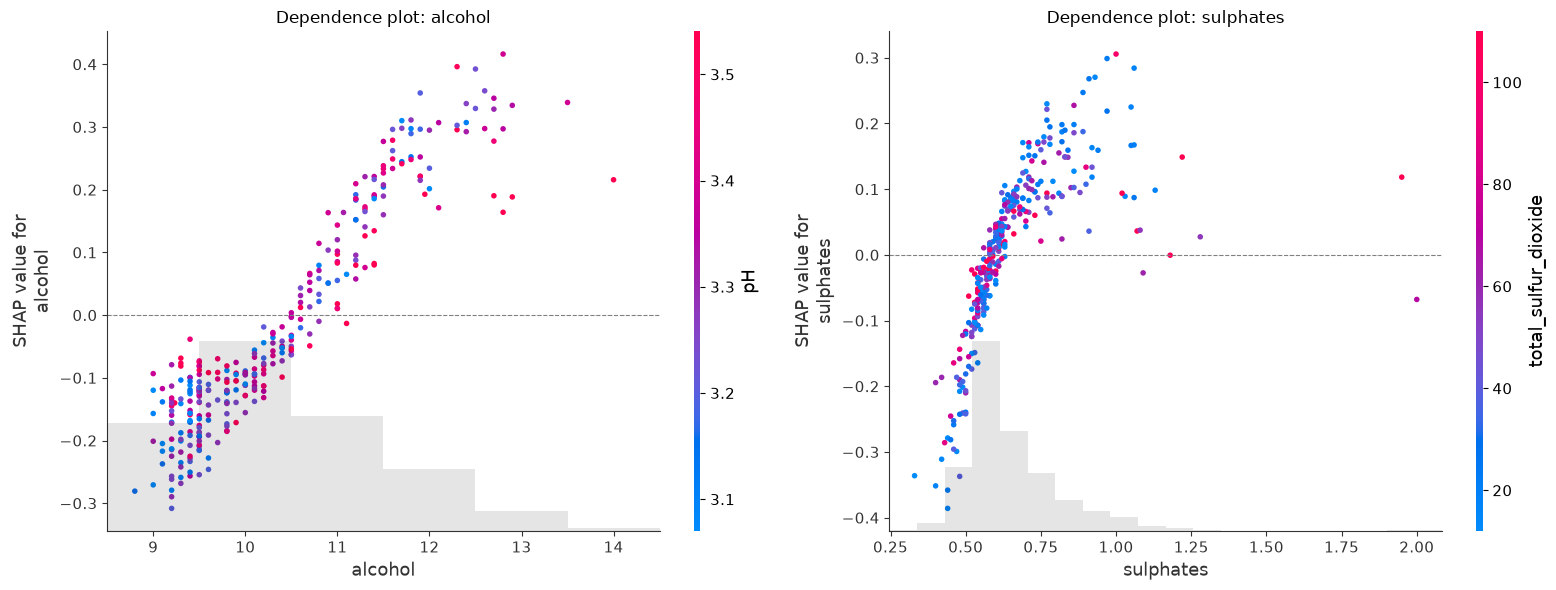

In [34]:
# Dependence plots: feature value (x) vs. its SHAP value (y), coloured by the feature it interacts with most
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for ax, feature in zip(axs, ['alcohol', 'sulphates']):
    shap.plots.scatter(sv[:, feature], color=sv, ax=ax, show=False)
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.set_title(f'Dependence plot: {feature}')
fig.tight_layout()
plt.show()

### Discussion (Task 6)

**Alcohol.** The SHAP value rises almost linearly from about −0.25 at 9 % to about +0.3 at 12 % and crosses zero at roughly 10.5 %, close to the typical alcohol content: wines above that push the prediction towards Good, wines below towards Poor. Above about 12 % the curve flattens into a plateau, because the explained output is a probability and saturates near P(good) = 1. The vertical spread at a given alcohol value (about ±0.1) shows no clear pattern in the colour feature selected by SHAP (pH), so the alcohol effect is largely additive; the spread mainly reflects how far the other features have already pushed the prediction.

**Sulphates.** The relationship is strongly non-linear: below about 0.6 there is a steep penalty zone (down to −0.4 at 0.35–0.45), above it the curve flattens to +0.1 to +0.3 between 0.75 and 1.0. Too little sulphates therefore hurts much more than a high level helps, matching the asymmetry in the beeswarm plot. Above about 1.0 the effect drops back to around zero. The histogram shows that hardly any training wines lie in this range, so this is extrapolation by the MLP and not a reliable pattern. The colouring by `total_sulfur_dioxide` suggests an interaction: for sulphates above 0.75, wines with high SO₂ receive clearly smaller positive contributions (≈0.1) than wines with low SO₂ (up to 0.3).

**Takeaway.** The dependence plots show what the global ranking cannot: the shape of the effect, thresholds, saturation, interactions, and regions where the model extrapolates beyond the training data.